# NLP Assignment 5 — Text Summarization with NLTK

Four summarization approaches — **Extractive**, **Abstractive**, **Generic** and **Query-based** — built and compared on an English document (Part C) and a Hindi document (Part D).

| Part | Abstractive model | Data |
|---|---|---|
| C — English | T5-small | Essay on AI in education, 1 465 words |
| D — Hindi | mT5 (XL-Sum) | Essay on the same topic, 933 words |

Three tunable parameters: summary ratio, number of sentences, frequency weight. Evaluation: ROUGE-1/2/L, compression ratio, content coverage.

---
## Part C — English: Extractive, Abstractive (T5), Generic and Query-based

### C1. Setup: install, imports, NLTK resources, objective

In [1]:
# ---- 1. Install Required Packages ----
import sys
import subprocess

subprocess.check_call(
    [sys.executable, "-m", "pip", "install", "-q", "rouge-score", "transformers", "sentencepiece"]
)

# ---- 2. Import Libraries ----
import re
import math
import random
import warnings

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from rouge_score import rouge_scorer

from transformers import T5Tokenizer, T5ForConditionalGeneration

from IPython.display import display

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid")

print("=" * 80)
print("LIBRARIES LOADED")
print("=" * 80)

# ---- 3. Download Nltk Resources ----
print("\nDownloading NLTK resources...")

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

print("NLTK resources downloaded successfully.")

# ---- 4. Title And Objective ----
print("\n" + "=" * 80)
print("NLP TEXT SUMMARIZATION PROJECT")
print("=" * 80)

print("""
OBJECTIVE
---------
Build and compare four types of text summarization:

1. Extractive Summarization
2. Abstractive Summarization
3. Generic Summarization
4. Query-Based Summarization

The project uses an English document about:
"The Impact of Artificial Intelligence on Education"

Evaluation metrics:
- ROUGE-1
- ROUGE-2
- ROUGE-L
- Compression Ratio
- Content Coverage

Three tunable parameters:
- Summary Ratio
- Number of Sentences
- Frequency Weight
""")

LIBRARIES LOADED

NLTK resources downloaded successfully.

NLP TEXT SUMMARIZATION PROJECT

OBJECTIVE
---------
Build and compare four types of text summarization:

1. Extractive Summarization
2. Abstractive Summarization
3. Generic Summarization
4. Query-Based Summarization

The project uses an English document about:
"The Impact of Artificial Intelligence on Education"

Evaluation metrics:
- ROUGE-1
- ROUGE-2
- ROUGE-L
- Compression Ratio
- Content Coverage

Three tunable parameters:
- Summary Ratio
- Number of Sentences
- Frequency Weight



### C2. Data: dummy document and reference summary

In [2]:
# ---- 5. Create Dummy Document ----
document = """
Artificial intelligence is becoming one of the most influential technologies
in modern education. Schools, colleges, universities, and online learning
platforms are increasingly using artificial intelligence to support teachers,
students, administrators, and researchers. AI systems can analyze large
amounts of information, identify patterns in student behavior, provide
personalized recommendations, and automate repetitive educational tasks.
Although artificial intelligence creates many opportunities, its introduction
also raises important questions about privacy, fairness, academic integrity,
teacher responsibilities, and the future of human-centered education.

One of the most important benefits of artificial intelligence in education is
personalized learning. Traditional classrooms require teachers to provide
instruction to groups of students who may have very different levels of
knowledge and learning speeds. AI-powered systems can analyze a student's
previous answers, learning history, and interactions with digital lessons.
Based on this information, the system can recommend exercises, explanations,
examples, and learning resources. Students who need additional practice can
receive easier exercises, while advanced students can receive more challenging
material.

Intelligent tutoring systems are another important application of AI. These
systems can provide immediate feedback when students make mistakes. Instead
of waiting for an assignment to be graded, students can receive explanations
during the learning process. Some intelligent tutoring systems identify
common mistakes and recommend targeted activities. This can be particularly
useful in mathematics, programming, science, and language learning, where
students benefit from frequent practice. However, automated feedback must be
designed carefully because incorrect recommendations may confuse students.

Artificial intelligence can also assist teachers with administrative work.
Educators spend considerable time preparing teaching materials, organizing
information, checking assignments, answering repeated questions, and
monitoring student progress. AI tools can generate practice questions,
classify responses, summarize classroom information, and identify students
who may require additional support. By reducing repetitive tasks, AI may give
teachers more time for mentoring, classroom discussion, creative activities,
lesson planning, and individual relationships with students.

Automated assessment is another area in which AI is being used. AI systems
can help grade objective questions and analyze written responses. Natural
language processing can identify themes, common mistakes, and important
concepts in student writing. Faster assessment can allow students to receive
feedback sooner. However, automated grading has limitations. Writing quality
can depend on context, creativity, culture, and the purpose of an assignment.
An algorithm that relies heavily on surface patterns may incorrectly judge a
creative or unusual response. Human teachers remain important for complex
assessment and final academic decisions.

Artificial intelligence can also improve accessibility. Speech recognition
can convert spoken language into text, while text-to-speech systems can read
digital material aloud. Translation systems can help students who speak
different languages, and intelligent interfaces can make educational content
easier to access. These technologies can reduce barriers for students with
disabilities and learners studying in multilingual environments. However,
accessibility systems must be tested with diverse users because technology
that works well for one group may not work equally well for another.

AI can support educational research and institutional decision-making.
Universities collect information about enrollment, course participation,
student performance, and graduation patterns. Data analysis systems can
identify trends and possible risk factors. For example, an institution may
discover that students who struggle in an introductory course are more likely
to discontinue a program. Advisors can use this information to provide
additional support. Predictive systems should not be treated as perfect
predictions because students are influenced by many personal, social,
economic, and academic factors.

The increasing use of AI creates important privacy concerns. Educational
institutions may collect information about student performance, behavior,
interests, communication, and learning activities. If this information is
stored or processed by poorly designed systems, students may lose control
over their personal data. Schools and universities need clear policies about
what information is collected, why it is collected, who can access it, and
how long it is retained. Data security should be an essential part of every
educational AI project.

Fairness and algorithmic bias are additional concerns. Artificial intelligence
systems learn patterns from data, and historical data can contain inequalities
or incomplete representations of different populations. A prediction system
might produce different outcomes for different groups of students. If these
predictions are used for admission, intervention, grading, or other important
decisions, biased outputs can have serious consequences. Developers and
educators should test systems across diverse populations, monitor results,
document limitations, and provide mechanisms for human review.

Academic integrity is another major issue. Generative AI systems can produce
essays, explanations, computer programs, and answers to questions. These
capabilities can help students brainstorm ideas, receive explanations, and
practice skills. At the same time, students may use AI to complete assignments
without developing the underlying knowledge and skills. Educational
institutions are therefore reconsidering traditional assessment methods.
Teachers may use oral examinations, classroom activities, project
demonstrations, drafts, reflections, and personalized discussions to evaluate
student learning.

Teachers themselves need appropriate training to use artificial intelligence
effectively. Providing an AI tool does not guarantee better education.
Educators need to understand how a system works, what errors it can make,
how generated information should be evaluated, and when human judgment
should override an automated recommendation. Professional development should
include AI literacy, data privacy, responsible technology use, and methods
for evaluating AI-generated content.

Students also need AI literacy. Future graduates are likely to encounter
artificial intelligence in universities, workplaces, government services,
and everyday applications. Students should understand both the capabilities
and limitations of intelligent systems. Learning to verify information,
recognize bias, protect personal data, cite sources appropriately, and use AI
as a learning assistant rather than a replacement for thinking will become
increasingly important.

There is also a question about the role of human interaction. Education is
not simply the transfer of information from a computer system to a learner.
Teachers provide encouragement, motivation, social guidance, emotional
support, and opportunities for collaboration. Classmates contribute through
discussion, teamwork, debate, and shared experiences. AI can simulate some
forms of interaction, but it cannot fully replace the social and human
dimensions of education.

The cost of implementing AI is another practical issue. Advanced systems
require computing infrastructure, software, technical expertise, maintenance,
and staff training. Wealthier institutions may be able to adopt sophisticated
systems more quickly than schools with limited resources. If technology
adoption is not accompanied by investment in infrastructure and teacher
training, the digital divide may increase. Educational leaders should
therefore consider affordability, sustainability, and equitable access.

Despite these challenges, artificial intelligence has the potential to improve
education when it is used responsibly. The strongest approach is not to treat
AI as a complete replacement for traditional teaching, but to combine
computational capabilities with human expertise. AI can process large
quantities of information quickly, identify patterns, personalize practice,
and automate repetitive tasks. Teachers can provide context, judgment,
creativity, encouragement, and ethical guidance.

The future of artificial intelligence in education will depend on thoughtful
implementation. Educational institutions should establish transparent
policies, protect student data, evaluate systems for bias, train teachers and
students, and continuously measure educational outcomes. Researchers should
also study whether AI tools actually improve learning rather than assuming
that technological sophistication automatically produces better results.

Overall, artificial intelligence is likely to remain an important part of the
future of education. It can support personalized learning, accessibility,
assessment, research, and administrative efficiency. At the same time,
privacy, fairness, academic integrity, cost, and human interaction must
remain central considerations. The goal should not be to maximize the amount
of AI used in education. Instead, the goal should be to use appropriate
technology to improve learning outcomes while preserving human judgment,
meaningful relationships, and equal educational opportunities.
"""

# ---- 6. Reference Summary ----
reference_summary = """
Artificial intelligence is increasingly influencing education through
personalized learning, intelligent tutoring, assessment, accessibility,
research, and administrative support. AI systems can analyze student
performance, recommend learning activities, provide immediate feedback, and
reduce repetitive work for teachers. These capabilities can give educators
more time for mentoring, creativity, discussion, and individual support.

AI can also improve accessibility through speech recognition, text-to-speech,
translation, and other assistive technologies. However, educational AI has
important risks. Privacy is a concern because institutions may collect
detailed information about students. Algorithmic bias can create unfair
outcomes when systems learn from incomplete or biased data. Automated
assessment may also fail to understand creativity, context, and unusual
responses.

Generative AI creates additional academic integrity challenges because
students can use it to produce assignments without developing their own
skills. Teachers and students therefore need AI literacy and clear guidelines.
Human interaction remains essential because teachers provide motivation,
judgment, emotional support, creativity, and social guidance that technology
cannot fully replace.

The most effective approach is to combine AI capabilities with human
expertise. Educational institutions should protect data, evaluate systems
for bias, train users, consider affordability, and measure actual learning
outcomes. AI should support rather than replace teachers, with the goal of
improving learning while preserving fairness, human relationships, and equal
educational opportunities.
"""

print("\nOriginal document words:", len(word_tokenize(document)))
print("Reference summary words:", len(word_tokenize(reference_summary)))


Original document words: 1465
Reference summary words: 252


### C3. Preprocessing and tunable parameters

In [3]:
# ---- 7. Nltk Preprocessing ----
print("\n" + "=" * 80)
print("ORIGINAL DOCUMENT")
print("=" * 80)
print(document.strip())

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_words(text):
    """
    NLTK preprocessing:
    1. Lowercase
    2. Word tokenization
    3. Punctuation removal
    4. Stopword removal
    5. Lemmatization
    """
    tokens = word_tokenize(text.lower())
    clean_words = []
    for token in tokens:
        if not token.isalpha():
            continue
        if token in stop_words:
            continue
        token = lemmatizer.lemmatize(token)
        clean_words.append(token)
    return clean_words

def get_sentences(text):
    return sent_tokenize(text)

def word_count(text):
    """
    Consistent word-count function used throughout the project.
    """
    return len([word for word in word_tokenize(text) if word.isalpha()])

def get_word_frequencies(text):
    words = preprocess_words(text)
    frequencies = Counter(words)
    if not frequencies:
        return {}
    maximum = max(frequencies.values())
    return {word: count / maximum for word, count in frequencies.items()}

print("\n" + "=" * 80)
print("PREPROCESSING")
print("=" * 80)

print("Number of sentences:", len(get_sentences(document)))

print("Number of meaningful words:", len(preprocess_words(document)))

print("\nTop 20 meaningful words:")

print(Counter(preprocess_words(document)).most_common(20))

# ---- 8. Three Tunable Parameters ----
summary_ratio = 0.20
num_sentences = 5
frequency_weight = 0.70

print("\n" + "=" * 80)
print("THREE TUNABLE PARAMETERS")
print("=" * 80)

print("1. Summary Ratio =", summary_ratio)
print("2. Number of Sentences =", num_sentences)
print("3. Frequency Weight =", frequency_weight)

print("""
Summary Ratio:
Controls the target percentage of the document retained.

Number of Sentences:
Controls the maximum number of sentences.

Frequency Weight:
Controls the balance between word frequency and sentence position
inside the Generic summarizer.

Position Weight = 1 - Frequency Weight
""")

# ---- 9. Determine Summary Length ----
def calculate_target_sentences(text, summary_ratio, num_sentences):
    """
    Summary Ratio determines the target length.
    Number of Sentences acts as an upper limit.
    This allows both parameters to have meaningful effects.
    """
    sentences = sent_tokenize(text)
    if not sentences:
        return 0
    ratio_target = max(1, round(len(sentences) * summary_ratio))
    target = min(ratio_target, num_sentences, len(sentences))
    return max(1, target)

def select_top_sentences(sentences, scores, number_to_select):
    if not sentences:
        return ""
    ranked_indices = sorted(range(len(sentences)), key=lambda i: (-scores[i], i))
    selected_indices = sorted(ranked_indices[:number_to_select])
    return " ".join(sentences[i] for i in selected_indices)


ORIGINAL DOCUMENT
Artificial intelligence is becoming one of the most influential technologies
in modern education. Schools, colleges, universities, and online learning
platforms are increasingly using artificial intelligence to support teachers,
students, administrators, and researchers. AI systems can analyze large
amounts of information, identify patterns in student behavior, provide
personalized recommendations, and automate repetitive educational tasks.
Although artificial intelligence creates many opportunities, its introduction
also raises important questions about privacy, fairness, academic integrity,
teacher responsibilities, and the future of human-centered education.

One of the most important benefits of artificial intelligence in education is
personalized learning. Traditional classrooms require teachers to provide
instruction to groups of students who may have very different levels of
knowledge and learning speeds. AI-powered systems can analyze a student's
previous ans

### C4. Extractive, Generic and Query-based summarizers

In [4]:
# ---- 10. Extractive Summarizer ----
def extractive_summarizer(text, summary_ratio=0.20, num_sentences=5):
    sentences = sent_tokenize(text)
    if not sentences:
        return ""
    target = calculate_target_sentences(text, summary_ratio, num_sentences)
    frequencies = get_word_frequencies(text)
    scores = []
    for sentence in sentences:
        words = preprocess_words(sentence)
        if not words:
            scores.append(0)
            continue
        score = sum(frequencies.get(word, 0) for word in words)
        score /= len(words)
        scores.append(score)
    return select_top_sentences(sentences, scores, target)

# ---- 11. Generic Summarizer ----
def generic_summarizer(text, summary_ratio=0.20, num_sentences=5, frequency_weight=0.70):
    """
    Generic summarization.
    It does NOT use a query.
    It combines:
    - word frequency
    - sentence position
    - sentence content/length
    Frequency Weight is configurable.
    """
    sentences = sent_tokenize(text)
    if not sentences:
        return ""
    target = calculate_target_sentences(text, summary_ratio, num_sentences)
    frequencies = get_word_frequencies(text)
    position_weight = 1 - frequency_weight
    scores = []
    total_sentences = len(sentences)
    for index, sentence in enumerate(sentences):
        words = preprocess_words(sentence)
        if words:
            frequency_score = sum(frequencies.get(word, 0) for word in words) / len(words)
        else:
            frequency_score = 0
        # Beginning sentences receive slightly higher scores.
        position_score = (total_sentences - index) / total_sentences
        # Content/length normalization.
        if words:
            length_score = min(len(words) / 20, 1.0)
        else:
            length_score = 0
        final_score = (
            frequency_weight * frequency_score + position_weight * position_score + 0.10 * length_score
        )
        scores.append(final_score)
    return select_top_sentences(sentences, scores, target)

# ---- 12. Query-Based Summarizer ----
def query_based_summarizer(text, query, summary_ratio=0.20, num_sentences=5):
    sentences = sent_tokenize(text)
    if not sentences:
        return ""
    target = calculate_target_sentences(text, summary_ratio, num_sentences)
    documents = [query] + sentences
    vectorizer = TfidfVectorizer(stop_words="english")
    matrix = vectorizer.fit_transform(documents)
    query_vector = matrix[0]
    sentence_vectors = matrix[1:]
    similarities = cosine_similarity(query_vector, sentence_vectors).flatten()
    frequencies = get_word_frequencies(text)
    scores = []
    for index, sentence in enumerate(sentences):
        words = preprocess_words(sentence)
        if words:
            frequency_score = sum(frequencies.get(word, 0) for word in words) / len(words)
        else:
            frequency_score = 0
        final_score = 0.80 * similarities[index] + 0.20 * frequency_score
        scores.append(final_score)
    return select_top_sentences(sentences, scores, target)

### C5. Abstractive summarizer (T5-small)

In [5]:
# ---- 13. Load T5 For Abstractive Summarization ----
print("\n" + "=" * 80)
print("LOADING T5 ABSTRACTIVE MODEL")
print("=" * 80)

model_name = "t5-small"

tokenizer = T5Tokenizer.from_pretrained(model_name)

model = T5ForConditionalGeneration.from_pretrained(model_name)

print("T5-small loaded successfully.")

# ---- 14. T5 Chunking Function ----
def split_into_chunks(text, max_words=250):
    """
    Splits a document into manageable word chunks.
    This prevents the abstractive model from only seeing
    the first part of a long document.
    """
    words = text.split()
    chunks = []
    for i in range(0, len(words), max_words):
        chunks.append(" ".join(words[i : i + max_words]))
    return chunks

def generate_t5_summary(text, max_length=100, min_length=30):
    input_text = "summarize: " + text
    inputs = tokenizer(input_text, return_tensors="pt", max_length=512, truncation=True)
    output = model.generate(
        **inputs,
        max_length=max_length,
        min_length=min(min_length, max_length - 1),
        num_beams=4,
        length_penalty=1.0,
        no_repeat_ngram_size=3,
        early_stopping=True
    )
    return tokenizer.decode(output[0], skip_special_tokens=True)

# ---- 15. Abstractive Summarizer ----
def abstractive_summarizer(text, summary_ratio=0.20, num_sentences=5):
    """
    Abstractive summarization using T5.
    The document is divided into chunks.
    Each chunk is summarized.
    The intermediate summaries are then combined
    and summarized again.
    """
    chunks = split_into_chunks(text, max_words=250)
    intermediate_summaries = []
    for chunk in chunks:
        chunk_summary = generate_t5_summary(chunk, max_length=80, min_length=20)
        if chunk_summary.strip():
            intermediate_summaries.append(chunk_summary)
    if not intermediate_summaries:
        return ""
    combined = " ".join(intermediate_summaries)
    final_word_target = max(40, min(130, int(word_count(text) * summary_ratio)))
    # If combined text is already short,
    # use it directly.
    if word_count(combined) <= final_word_target:
        return combined
    final_summary = generate_t5_summary(
        combined, max_length=final_word_target, min_length=max(20, min(50, final_word_target // 2))
    )
    return final_summary


LOADING T5 ABSTRACTIVE MODEL


tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5-small loaded successfully.


### C6. Generate and display the four summaries

In [6]:
# ---- 16. Query ----
query = "How does artificial intelligence affect " "teachers and students?"

# ---- 17. Generate Four Summaries ----
print("\n" + "=" * 80)
print("GENERATING FOUR SUMMARIES")
print("=" * 80)

summaries = {}

# ------------------------------------------------
# 1. Extractive
# ------------------------------------------------

summaries["Extractive"] = extractive_summarizer(document, summary_ratio, num_sentences)

# ------------------------------------------------
# 2. Abstractive
# ------------------------------------------------

print("\nGenerating abstractive summary...")

summaries["Abstractive"] = abstractive_summarizer(document, summary_ratio, num_sentences)

# ------------------------------------------------
# 3. Generic
# ------------------------------------------------

summaries["Generic"] = generic_summarizer(document, summary_ratio, num_sentences, frequency_weight)

# ------------------------------------------------
# 4. Query-Based
# ------------------------------------------------

summaries["Query-Based"] = query_based_summarizer(document, query, summary_ratio, num_sentences)

# ---- 18. Display Summaries ----
for method, summary in summaries.items():

    print("\n" + "=" * 80)
    print(method.upper() + " SUMMARY")
    print("=" * 80)
    if method == "Query-Based":
        print("Query:", query)
        print()
    print(summary)
    print("\nSentence count:", len(sent_tokenize(summary)))
    print("Word count:", word_count(summary))


GENERATING FOUR SUMMARIES

Generating abstractive summary...

EXTRACTIVE SUMMARY
Intelligent tutoring systems are another important application of AI. These
systems can provide immediate feedback when students make mistakes. A prediction system
might produce different outcomes for different groups of students. Students also need AI literacy. Students should understand both the capabilities
and limitations of intelligent systems.

Sentence count: 5
Word count: 47

ABSTRACTIVE SUMMARY
artificial intelligence is becoming one of the most influential technologies in modern education. schools, colleges, universities, and online learning platforms are increasingly using artificial intelligence to support teachers, students, administrators, and researchers. AI-powered systems can analyze large amounts of information, identify patterns in student behavior, provide personalized recommendations.

Sentence count: 3
Word count: 47

GENERIC SUMMARY
Schools, colleges, universities, and online learni

### C7. Evaluation: statistics, ROUGE, content coverage, final table

In [7]:
# ---- 19. Summary Statistics ----
def compression_ratio(summary, original):
    original_words = word_count(original)
    if original_words == 0:
        return 0
    return word_count(summary) / original_words

statistics = []

for method, summary in summaries.items():

    statistics.append(
        {
            "Method": method,
            "Sentences": len(sent_tokenize(summary)),
            "Words": word_count(summary),
            "Compression Ratio": compression_ratio(summary, document),
        }
    )

summary_stats_df = pd.DataFrame(statistics)

print("\n" + "=" * 80)
print("SUMMARY STATISTICS")
print("=" * 80)

display(summary_stats_df.style.format({"Compression Ratio": "{:.3f}"}))

# ---- 20. Rouge Evaluation ----
rouge_scorer_object = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

def evaluate_rouge(summary, reference):
    scores = rouge_scorer_object.score(reference, summary)
    return {
        "ROUGE-1 Precision": scores["rouge1"].precision,
        "ROUGE-1 Recall": scores["rouge1"].recall,
        "ROUGE-1 F1": scores["rouge1"].fmeasure,
        "ROUGE-2 Precision": scores["rouge2"].precision,
        "ROUGE-2 Recall": scores["rouge2"].recall,
        "ROUGE-2 F1": scores["rouge2"].fmeasure,
        "ROUGE-L Precision": scores["rougeL"].precision,
        "ROUGE-L Recall": scores["rougeL"].recall,
        "ROUGE-L F1": scores["rougeL"].fmeasure,
    }

rouge_results = []

for method, summary in summaries.items():

    scores = evaluate_rouge(summary, reference_summary)
    rouge_results.append({"Method": method, **scores})

rouge_df = pd.DataFrame(rouge_results)

print("\n" + "=" * 80)
print("ROUGE EVALUATION")
print("=" * 80)

display(rouge_df.style.format({column: "{:.3f}" for column in rouge_df.columns if column != "Method"}))

# ---- 21. Content Coverage ----
def content_coverage(summary, reference, threshold=0.15):
    """
    Content Coverage:
    1. Split reference summary into sentences.
    2. Split generated summary into sentences.
    3. Convert sentences to TF-IDF vectors.
    4. Calculate cosine similarity.
    5. For each reference sentence, find its best matching
       generated sentence.
    6. A reference sentence is considered covered if its
       similarity is >= threshold.
    Coverage =
        covered reference sentences /
        total reference sentences
    """
    reference_sentences = sent_tokenize(reference)
    summary_sentences = sent_tokenize(summary)
    if not reference_sentences:
        return 0
    if not summary_sentences:
        return 0
    combined = reference_sentences + summary_sentences
    vectorizer = TfidfVectorizer(stop_words="english")
    try:
        matrix = vectorizer.fit_transform(combined)
    except ValueError:
        return 0
    reference_matrix = matrix[: len(reference_sentences)]
    summary_matrix = matrix[len(reference_sentences) :]
    similarities = cosine_similarity(reference_matrix, summary_matrix)
    best_similarity = similarities.max(axis=1)
    covered = np.sum(best_similarity >= threshold)
    return covered / len(reference_sentences)

coverage_results = []

for method, summary in summaries.items():

    coverage_results.append(
        {
            "Method": method,
            "Content Coverage": content_coverage(summary, reference_summary),
            "Compression Ratio": compression_ratio(summary, document),
        }
    )

coverage_df = pd.DataFrame(coverage_results)

print("\n" + "=" * 80)
print("ADDITIONAL EVALUATION METRICS")
print("=" * 80)

display(coverage_df.style.format({"Content Coverage": "{:.3f}", "Compression Ratio": "{:.3f}"}))

# ---- 22. Final Performance Table ----
final_df = rouge_df[["Method", "ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1"]].merge(coverage_df, on="Method")

final_df["Overall Score"] = final_df[["ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1"]].mean(axis=1)

final_df = final_df.sort_values("Overall Score", ascending=False).reset_index(drop=True)

print("\n" + "=" * 80)
print("FINAL CONSOLIDATED RESULTS")
print("=" * 80)

display(
    final_df.style.format(
        {
            "ROUGE-1 F1": "{:.3f}",
            "ROUGE-2 F1": "{:.3f}",
            "ROUGE-L F1": "{:.3f}",
            "Content Coverage": "{:.3f}",
            "Compression Ratio": "{:.3f}",
            "Overall Score": "{:.3f}",
        }
    )
)


SUMMARY STATISTICS


,Method,Sentences,Words,Compression Ratio
0,Extractive,5,47,0.038
1,Abstractive,3,47,0.038
2,Generic,5,73,0.059
3,Query-Based,5,58,0.047



ROUGE EVALUATION


,Method,ROUGE-1 Precision,ROUGE-1 Recall,ROUGE-1 F1,ROUGE-2 Precision,ROUGE-2 Recall,ROUGE-2 F1,ROUGE-L Precision,ROUGE-L Recall,ROUGE-L F1
0,Extractive,0.681,0.152,0.248,0.130,0.029,0.047,0.404,0.090,0.147
1,Abstractive,0.592,0.137,0.223,0.104,0.024,0.039,0.286,0.066,0.108
2,Generic,0.632,0.227,0.334,0.093,0.033,0.049,0.289,0.104,0.153
3,Query-Based,0.638,0.175,0.275,0.123,0.033,0.052,0.259,0.071,0.112



ADDITIONAL EVALUATION METRICS


,Method,Content Coverage,Compression Ratio
0,Extractive,0.286,0.038
1,Abstractive,0.143,0.038
2,Generic,0.214,0.059
3,Query-Based,0.357,0.047



FINAL CONSOLIDATED RESULTS


,Method,ROUGE-1 F1,ROUGE-2 F1,ROUGE-L F1,Content Coverage,Compression Ratio,Overall Score
0,Generic,0.334,0.049,0.153,0.214,0.059,0.179
1,Extractive,0.248,0.047,0.147,0.286,0.038,0.147
2,Query-Based,0.275,0.052,0.112,0.357,0.047,0.146
3,Abstractive,0.223,0.039,0.108,0.143,0.038,0.123


### C8. Parameter tuning (all four methods)

In [8]:
# ---- 23. Parameter Tuning ----
summary_ratios = [0.10, 0.20, 0.30]

sentence_values = [3, 5, 8]

frequency_weights = [0.30, 0.50, 0.70]

print("\n" + "=" * 80)
print("PARAMETER TUNING EXPERIMENT")
print("=" * 80)

print("Summary ratios:", summary_ratios)

print("Sentence values:", sentence_values)

print("Frequency weights:", frequency_weights)

tuning_results = []

# ---- 24. Tuning: Extractive ----
for ratio in summary_ratios:

    for sentence_limit in sentence_values:
        summary = extractive_summarizer(document, ratio, sentence_limit)
        scores = evaluate_rouge(summary, reference_summary)
        tuning_results.append(
            {
                "Method": "Extractive",
                "Summary Ratio": ratio,
                "Number of Sentences": sentence_limit,
                "Frequency Weight": np.nan,
                "ROUGE-1": scores["ROUGE-1 F1"],
                "ROUGE-2": scores["ROUGE-2 F1"],
                "ROUGE-L": scores["ROUGE-L F1"],
                "Compression Ratio": compression_ratio(summary, document),
            }
        )

# ---- 25. Tuning: Generic ----
for ratio in summary_ratios:

    for sentence_limit in sentence_values:
        for weight in frequency_weights:
            summary = generic_summarizer(document, ratio, sentence_limit, weight)
            scores = evaluate_rouge(summary, reference_summary)
            tuning_results.append(
                {
                    "Method": "Generic",
                    "Summary Ratio": ratio,
                    "Number of Sentences": sentence_limit,
                    "Frequency Weight": weight,
                    "ROUGE-1": scores["ROUGE-1 F1"],
                    "ROUGE-2": scores["ROUGE-2 F1"],
                    "ROUGE-L": scores["ROUGE-L F1"],
                    "Compression Ratio": compression_ratio(summary, document),
                }
            )

# ---- 26. Tuning: Query-Based ----
for ratio in summary_ratios:

    for sentence_limit in sentence_values:
        summary = query_based_summarizer(document, query, ratio, sentence_limit)
        scores = evaluate_rouge(summary, reference_summary)
        tuning_results.append(
            {
                "Method": "Query-Based",
                "Summary Ratio": ratio,
                "Number of Sentences": sentence_limit,
                "Frequency Weight": np.nan,
                "ROUGE-1": scores["ROUGE-1 F1"],
                "ROUGE-2": scores["ROUGE-2 F1"],
                "ROUGE-L": scores["ROUGE-L F1"],
                "Compression Ratio": compression_ratio(summary, document),
            }
        )

# ---- 27. Tuning: Abstractive ----
#
# To keep the experiment manageable, abstractive tuning tests
# summary ratio and sentence limit combinations without repeatedly
# downloading/reloading the model.

print("\nRunning abstractive tuning...")

for ratio in summary_ratios:

    for sentence_limit in sentence_values:
        summary = abstractive_summarizer(document, ratio, sentence_limit)
        scores = evaluate_rouge(summary, reference_summary)
        tuning_results.append(
            {
                "Method": "Abstractive",
                "Summary Ratio": ratio,
                "Number of Sentences": sentence_limit,
                "Frequency Weight": np.nan,
                "ROUGE-1": scores["ROUGE-1 F1"],
                "ROUGE-2": scores["ROUGE-2 F1"],
                "ROUGE-L": scores["ROUGE-L F1"],
                "Compression Ratio": compression_ratio(summary, document),
            }
        )

# ---- 28. Create Tuning Dataframe ----
tuning_df = pd.DataFrame(tuning_results)

tuning_df["Overall Score"] = tuning_df[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean(axis=1)

print("\n" + "=" * 80)
print("TUNING RESULTS")
print("=" * 80)

display(
    tuning_df.head(30).style.format(
        {
            "Summary Ratio": "{:.2f}",
            "Frequency Weight": lambda x: "-" if pd.isna(x) else f"{x:.2f}",
            "ROUGE-1": "{:.3f}",
            "ROUGE-2": "{:.3f}",
            "ROUGE-L": "{:.3f}",
            "Compression Ratio": "{:.3f}",
            "Overall Score": "{:.3f}",
        }
    )
)

# ---- 29. Best Tuning Configuration ----
best_tuning = tuning_df.loc[tuning_df["Overall Score"].idxmax()]

print("\n" + "=" * 80)
print("BEST TUNING CONFIGURATION")
print("=" * 80)

print("Method:", best_tuning["Method"])

print("Summary Ratio:", best_tuning["Summary Ratio"])

print("Number of Sentences:", int(best_tuning["Number of Sentences"]))

if pd.isna(best_tuning["Frequency Weight"]):

    print("Frequency Weight: Not applicable")

else:

    print("Frequency Weight:", best_tuning["Frequency Weight"])

print("ROUGE-1:", round(best_tuning["ROUGE-1"], 4))

print("ROUGE-2:", round(best_tuning["ROUGE-2"], 4))

print("ROUGE-L:", round(best_tuning["ROUGE-L"], 4))

print("Overall Score:", round(best_tuning["Overall Score"], 4))


PARAMETER TUNING EXPERIMENT
Summary ratios: [0.1, 0.2, 0.3]
Sentence values: [3, 5, 8]
Frequency weights: [0.3, 0.5, 0.7]

Running abstractive tuning...

TUNING RESULTS


,Method,Summary Ratio,Number of Sentences,Frequency Weight,ROUGE-1,ROUGE-2,ROUGE-L,Compression Ratio,Overall Score
0,Extractive,0.10,3,-,0.186,0.043,0.127,0.021,0.118
1,Extractive,0.10,5,-,0.248,0.047,0.147,0.038,0.147
2,Extractive,0.10,8,-,0.355,0.071,0.168,0.077,0.198
3,Extractive,0.20,3,-,0.186,0.043,0.127,0.021,0.118
4,Extractive,0.20,5,-,0.248,0.047,0.147,0.038,0.147
5,Extractive,0.20,8,-,0.355,0.071,0.168,0.077,0.198
6,Extractive,0.30,3,-,0.186,0.043,0.127,0.021,0.118
7,Extractive,0.30,5,-,0.248,0.047,0.147,0.038,0.147
8,Extractive,0.30,8,-,0.355,0.071,0.168,0.077,0.198
9,Generic,0.10,3,0.30,0.310,0.036,0.166,0.052,0.171



BEST TUNING CONFIGURATION
Method: Generic
Summary Ratio: 0.1
Number of Sentences: 8
Frequency Weight: 0.5
ROUGE-1: 0.437
ROUGE-2: 0.0563
ROUGE-L: 0.1625
Overall Score: 0.2186


### C9. Visualisations

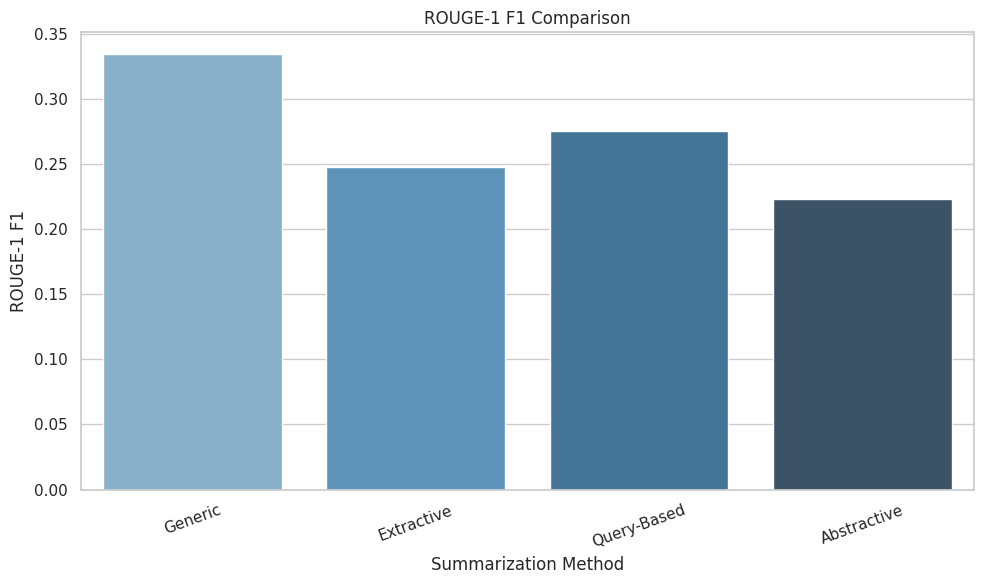

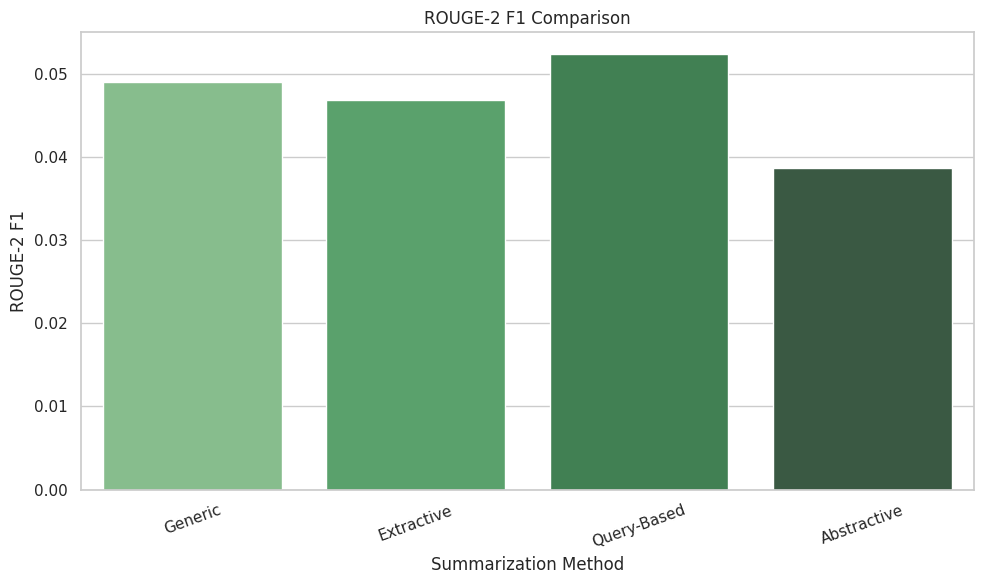

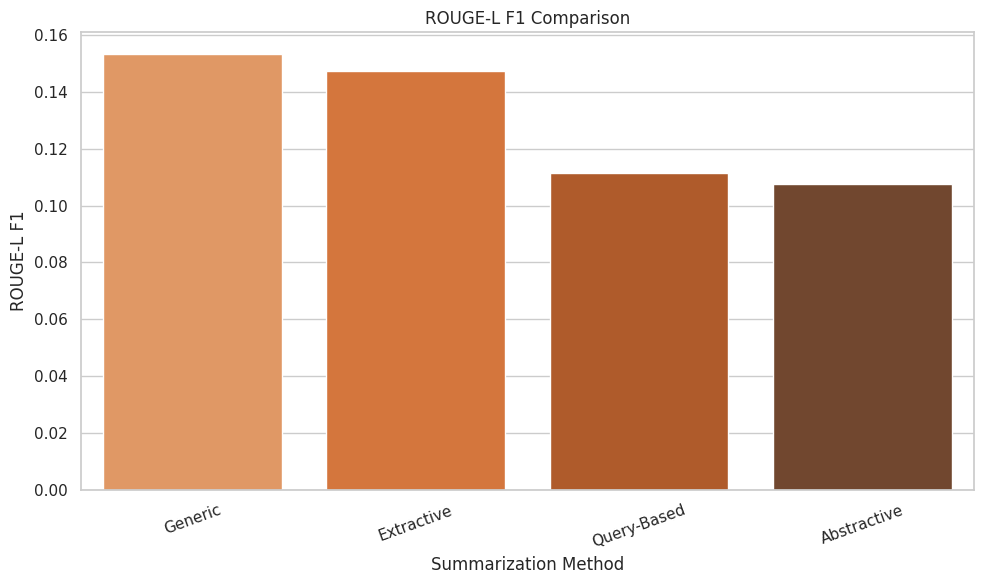

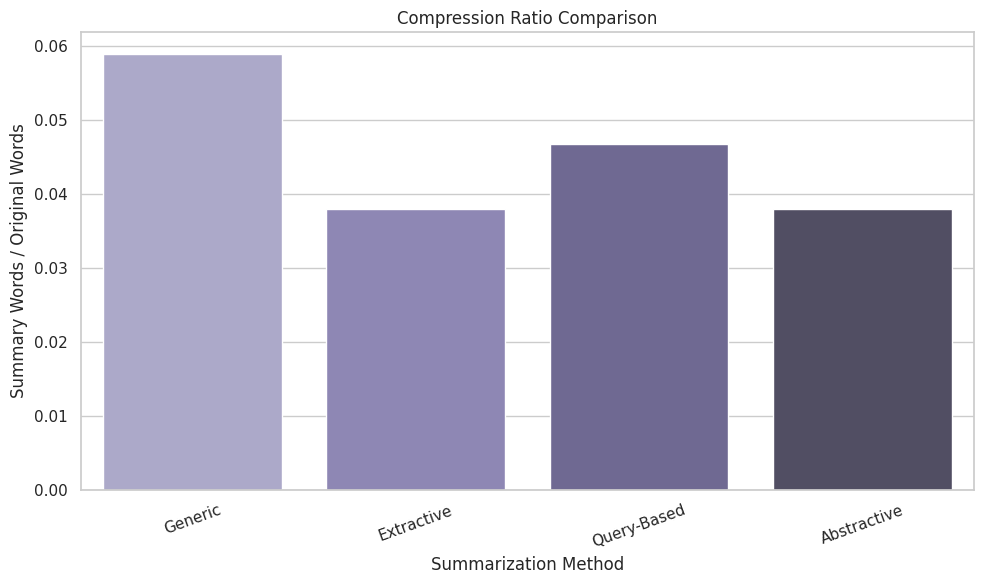

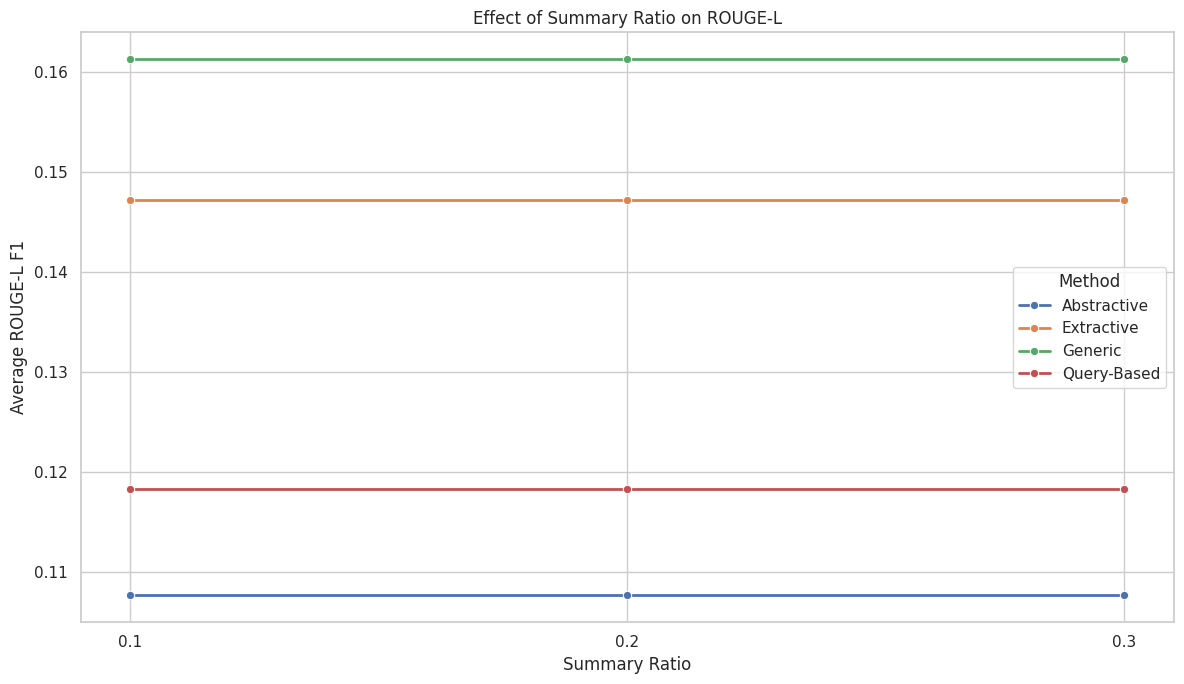

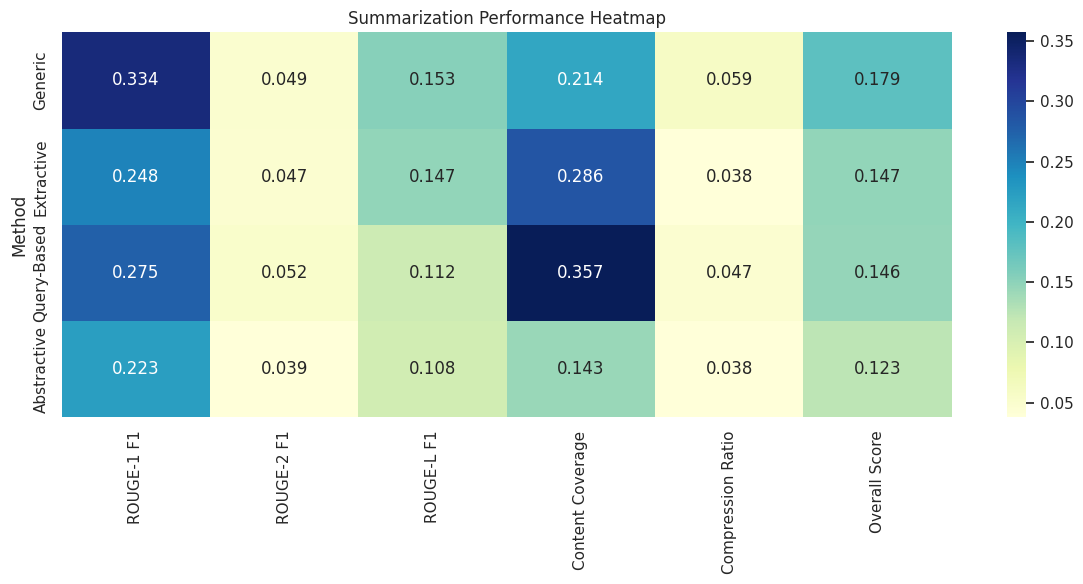

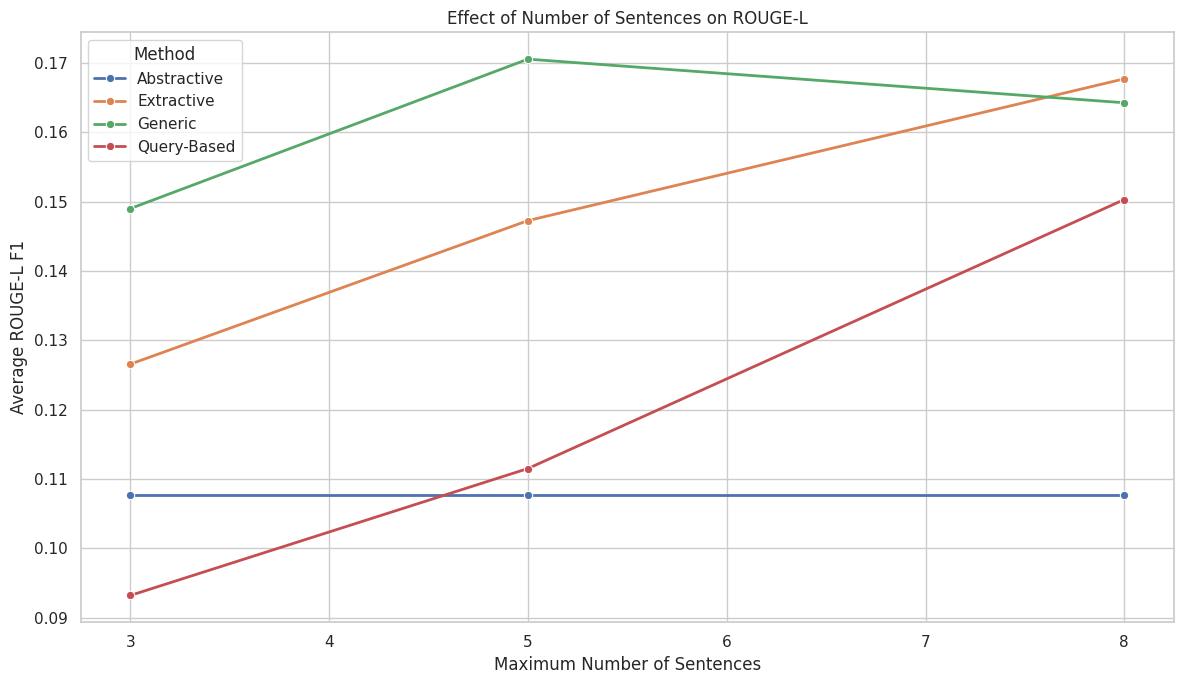

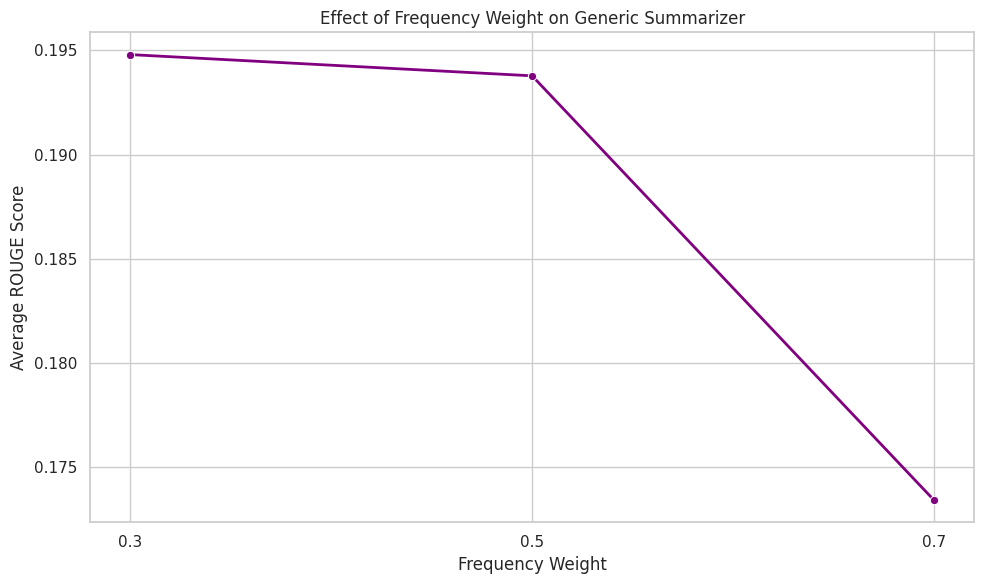

In [9]:
# ---- 30. Visualization 1 - Rouge-1 ----
plt.figure(figsize=(10, 6))

sns.barplot(data=final_df, x="Method", y="ROUGE-1 F1", palette="Blues_d")

plt.title("ROUGE-1 F1 Comparison")

plt.xlabel("Summarization Method")

plt.ylabel("ROUGE-1 F1")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

# ---- 31. Visualization 2 - Rouge-2 ----
plt.figure(figsize=(10, 6))

sns.barplot(data=final_df, x="Method", y="ROUGE-2 F1", palette="Greens_d")

plt.title("ROUGE-2 F1 Comparison")

plt.xlabel("Summarization Method")

plt.ylabel("ROUGE-2 F1")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

# ---- 32. Visualization 3 - Rouge-L ----
plt.figure(figsize=(10, 6))

sns.barplot(data=final_df, x="Method", y="ROUGE-L F1", palette="Oranges_d")

plt.title("ROUGE-L F1 Comparison")

plt.xlabel("Summarization Method")

plt.ylabel("ROUGE-L F1")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

# ---- 33. Visualization 4 - Compression ----
plt.figure(figsize=(10, 6))

sns.barplot(data=final_df, x="Method", y="Compression Ratio", palette="Purples_d")

plt.title("Compression Ratio Comparison")

plt.xlabel("Summarization Method")

plt.ylabel("Summary Words / Original Words")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

# ---- 34. Visualization 5 - Summary Ratio Vs Rouge-L ----
ratio_effect = tuning_df.groupby(["Method", "Summary Ratio"])["ROUGE-L"].mean().reset_index()

plt.figure(figsize=(12, 7))

sns.lineplot(data=ratio_effect, x="Summary Ratio", y="ROUGE-L", hue="Method", marker="o", linewidth=2)

plt.title("Effect of Summary Ratio on ROUGE-L")

plt.xlabel("Summary Ratio")

plt.ylabel("Average ROUGE-L F1")

plt.xticks(summary_ratios)

plt.legend(title="Method")

plt.tight_layout()

plt.show()

# ---- 35. Visualization 6 - Heatmap ----
heatmap_data = final_df.set_index("Method")[
    ["ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1", "Content Coverage", "Compression Ratio", "Overall Score"]
]

plt.figure(figsize=(12, 6))

sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlGnBu")

plt.title("Summarization Performance Heatmap")

plt.tight_layout()

plt.show()

# ---- 36. Effect Of Number Of Sentences ----
sentence_effect = tuning_df.groupby(["Method", "Number of Sentences"])["ROUGE-L"].mean().reset_index()

plt.figure(figsize=(12, 7))

sns.lineplot(
    data=sentence_effect, x="Number of Sentences", y="ROUGE-L", hue="Method", marker="o", linewidth=2
)

plt.title("Effect of Number of Sentences on ROUGE-L")

plt.xlabel("Maximum Number of Sentences")

plt.ylabel("Average ROUGE-L F1")

plt.legend(title="Method")

plt.tight_layout()

plt.show()

# ---- 37. Effect Of Frequency Weight ----
generic_weight_effect = (
    tuning_df[tuning_df["Method"] == "Generic"]
    .groupby("Frequency Weight")[["ROUGE-1", "ROUGE-2", "ROUGE-L"]]
    .mean()
    .reset_index()
)

generic_weight_effect["Overall"] = generic_weight_effect[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean(axis=1)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=generic_weight_effect, x="Frequency Weight", y="Overall", marker="o", linewidth=2, color="purple"
)

plt.title("Effect of Frequency Weight on Generic Summarizer")

plt.xlabel("Frequency Weight")

plt.ylabel("Average ROUGE Score")

plt.xticks(frequency_weights)

plt.tight_layout()

plt.show()

### C10. Best summarizer, qualitative comparison, parameter effects

In [10]:
# ---- 38. Best Summarizer ----
best_method = final_df.iloc[0]["Method"]
best_score = final_df.iloc[0]["Overall Score"]

worst_method = final_df.iloc[-1]["Method"]
worst_score = final_df.iloc[-1]["Overall Score"]

print("\n" + "=" * 80)
print("BEST SUMMARIZER")
print("=" * 80)

print("Best Summarizer:", best_method)

print("Best Overall Score:", round(best_score, 4))

print("\nWorst Summarizer:", worst_method)

print("Worst Overall Score:", round(worst_score, 4))

# ---- 39. Qualitative Comparison ----
print("\n" + "=" * 80)
print("QUALITATIVE COMPARISON")
print("=" * 80)

qualitative_explanations = {
    "Extractive": """
Selects complete sentences from the original document.
It preserves the author's original wording and is easy to interpret.
It may sometimes select sentences that contain important keywords but
do not form a perfectly coherent summary.
""",
    "Abstractive": """
Generates new wording rather than simply copying sentences.
It can combine information from different parts of the document and
produce a more natural summary. However, generative models can sometimes
produce inaccurate or overly general information.
""",
    "Generic": """
Creates a broad summary of the document without a specific user query.
The implementation combines word frequency, sentence position, and
content length. Increasing the frequency weight makes the method focus
more strongly on important keywords.
""",
    "Query-Based": """
Focuses on information relevant to a specific user query.
The query is converted into a TF-IDF vector and sentences are ranked
according to their similarity to the query. This makes the method useful
when the user wants information about a particular aspect of a document.
""",
}

for method, summary in summaries.items():

    print("\n" + "-" * 80)
    print(method.upper())
    print("-" * 80)
    print(qualitative_explanations[method])
    print("Generated Summary:")
    print(summary)

# ---- 40. Parameter Effect Analysis ----
ratio_scores = tuning_df.groupby("Summary Ratio")[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean()

ratio_scores["Mean ROUGE"] = ratio_scores.mean(axis=1)

sentence_scores = tuning_df.groupby("Number of Sentences")[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean()

sentence_scores["Mean ROUGE"] = sentence_scores.mean(axis=1)

weight_scores = (
    tuning_df[tuning_df["Method"] == "Generic"]
    .groupby("Frequency Weight")[["ROUGE-1", "ROUGE-2", "ROUGE-L"]]
    .mean()
)

weight_scores["Mean ROUGE"] = weight_scores.mean(axis=1)

print("\n" + "=" * 80)
print("PARAMETER EFFECT ANALYSIS")
print("=" * 80)

print("\nSummary Ratio Effect:")

display(ratio_scores.style.format("{:.3f}"))

print("\nNumber of Sentences Effect:")

display(sentence_scores.style.format("{:.3f}"))

print("\nFrequency Weight Effect:")

display(weight_scores.style.format("{:.3f}"))

# ---- 41. Determine Largest Parameter Effect ----
ratio_effect_size = ratio_scores["Mean ROUGE"].max() - ratio_scores["Mean ROUGE"].min()

sentence_effect_size = sentence_scores["Mean ROUGE"].max() - sentence_scores["Mean ROUGE"].min()

weight_effect_size = weight_scores["Mean ROUGE"].max() - weight_scores["Mean ROUGE"].min()

parameter_effects = {
    "Summary Ratio": ratio_effect_size,
    "Number of Sentences": sentence_effect_size,
    "Frequency Weight": weight_effect_size,
}

largest_parameter = max(parameter_effects, key=parameter_effects.get)


BEST SUMMARIZER
Best Summarizer: Generic
Best Overall Score: 0.179

Worst Summarizer: Abstractive
Worst Overall Score: 0.1232

QUALITATIVE COMPARISON

--------------------------------------------------------------------------------
EXTRACTIVE
--------------------------------------------------------------------------------

Selects complete sentences from the original document.
It preserves the author's original wording and is easy to interpret.
It may sometimes select sentences that contain important keywords but
do not form a perfectly coherent summary.

Generated Summary:
Intelligent tutoring systems are another important application of AI. These
systems can provide immediate feedback when students make mistakes. A prediction system
might produce different outcomes for different groups of students. Students also need AI literacy. Students should understand both the capabilities
and limitations of intelligent systems.

-----------------------------------------------------------------

,ROUGE-1,ROUGE-2,ROUGE-L,Mean ROUGE
Summary Ratio,,,,
0.100000,0.300,0.047,0.143,0.163
0.200000,0.300,0.047,0.143,0.163
0.300000,0.300,0.047,0.143,0.163



Number of Sentences Effect:


,ROUGE-1,ROUGE-2,ROUGE-L,Mean ROUGE
Number of Sentences,,,,
3,0.245,0.041,0.129,0.138
5,0.300,0.046,0.146,0.164
8,0.356,0.055,0.153,0.188



Frequency Weight Effect:


,ROUGE-1,ROUGE-2,ROUGE-L,Mean ROUGE
Frequency Weight,,,,
0.300000,0.362,0.044,0.178,0.195
0.500000,0.368,0.046,0.167,0.194
0.700000,0.330,0.052,0.138,0.173


### C11. Conclusion and final table

In [11]:
# ---- 42. Final Conclusion ----
print("\n" + "=" * 80)
print("PROJECT CONCLUSION")
print("=" * 80)

print(f"""
RESULTS
-------

The experiment compared four summarization approaches:

1. Extractive
2. Abstractive
3. Generic
4. Query-Based

Best-performing summarizer:
    {best_method}

Best Overall ROUGE Score:
    {best_score:.4f}

Lowest-performing summarizer:
    {worst_method}

Lowest Overall ROUGE Score:
    {worst_score:.4f}

PARAMETER ANALYSIS
------------------

The parameter showing the largest average effect on ROUGE was:

    {largest_parameter}

INTERPRETATION
--------------

Extractive summarization selects existing sentences from the document.
Its main advantage is that it preserves the original wording and does not
invent new information.

Abstractive summarization uses a T5 language model to generate new text.
It can combine ideas and produce more natural summaries, but generative
models may sometimes produce information that is not perfectly faithful
to the source.

Generic summarization creates a broad summary without requiring a query.
The implemented method combines word frequency, sentence position, and
content length.

Query-based summarization focuses specifically on a user's information
need. In this experiment the query was:

"{query}"

A query-based system can be useful when a document contains many topics
but the user is interested in only one particular topic.

SUMMARY LENGTH
--------------

A larger summary ratio or larger sentence limit generally allows more
information to be retained. This can increase ROUGE recall because more
reference information may appear in the generated summary.

However, increasing summary length also reduces compression and may
introduce redundant or less important sentences. Therefore, the best
summary is not necessarily the longest summary.

EVALUATION LIMITATIONS
----------------------

ROUGE measures overlap between the generated summary and reference summary.
Therefore, a summary may receive a lower ROUGE score even if it is useful,
coherent, and semantically correct.

The Content Coverage metric used here is also an approximate TF-IDF-based
measure and should not be interpreted as a perfect semantic evaluation.

The experiment uses only one dummy document and one manually written
reference summary. Therefore, the winning method cannot be considered
universally superior.

FUTURE WORK
-----------

Possible improvements include:

- BERT-based summarization
- BART
- PEGASUS
- Larger T5 models
- Transformer-based semantic similarity
- Abstractive summarization with larger datasets
- Multiple reference summaries
- Human evaluation
- Domain-specific datasets
- Multilingual summarization
- Redundancy detection
- Sentence embeddings
- Larger benchmark datasets
""")

# ---- 43. Final Table ----
print("\n" + "=" * 80)
print("FINAL RESULTS TABLE")
print("=" * 80)

final_display = final_df[
    ["Method", "ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1", "Compression Ratio", "Overall Score"]
].copy()

display(
    final_display.style.format(
        {
            "ROUGE-1 F1": "{:.3f}",
            "ROUGE-2 F1": "{:.3f}",
            "ROUGE-L F1": "{:.3f}",
            "Compression Ratio": "{:.3f}",
            "Overall Score": "{:.3f}",
        }
    )
)


PROJECT CONCLUSION

RESULTS
-------

The experiment compared four summarization approaches:

1. Extractive
2. Abstractive
3. Generic
4. Query-Based

Best-performing summarizer:
    Generic

Best Overall ROUGE Score:
    0.1790

Lowest-performing summarizer:
    Abstractive

Lowest Overall ROUGE Score:
    0.1232

PARAMETER ANALYSIS
------------------

The parameter showing the largest average effect on ROUGE was:

    Number of Sentences

INTERPRETATION
--------------

Extractive summarization selects existing sentences from the document.
Its main advantage is that it preserves the original wording and does not
invent new information.

Abstractive summarization uses a T5 language model to generate new text.
It can combine ideas and produce more natural summaries, but generative
models may sometimes produce information that is not perfectly faithful
to the source.

Generic summarization creates a broad summary without requiring a query.
The implemented method combines word frequency, s

,Method,ROUGE-1 F1,ROUGE-2 F1,ROUGE-L F1,Compression Ratio,Overall Score
0,Generic,0.334,0.049,0.153,0.059,0.179
1,Extractive,0.248,0.047,0.147,0.038,0.147
2,Query-Based,0.275,0.052,0.112,0.047,0.146
3,Abstractive,0.223,0.039,0.108,0.038,0.123


---
## Part D — Hindi Text Summarization

The same four approaches (Extractive, Abstractive, Generic, Query-based) applied to a Hindi document.
Part D is self-contained: it re-imports what it needs and defines Hindi-specific preprocessing.

What changes for Hindi:
1. **Sentence splitting** — NLTK's `sent_tokenize` does not recognise the Devanagari full stop `।`, so a regex splitter is used.
2. **Stopwords and lemmatisation** — NLTK has no Hindi stopword list or lemmatiser; a small stopword list is defined here and no lemmatisation is done.
3. **ROUGE tokenisation** — `rouge-score`'s default tokenizer keeps only `[a-z0-9]`, which deletes Devanagari and gives 0 for everything. A whitespace tokenizer is passed instead.
4. **Abstractive model** — T5-small is English-only. `csebuetnlp/mT5_multilingual_XLSum` (mT5 fine-tuned for summarisation in 45 languages, including Hindi) is used.

### D1. Imports and Hindi-specific preprocessing

In [12]:
import re
import math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from rouge_score import rouge_scorer
from IPython.display import display

# --- Hindi sentence splitter (handles । ? ! and Latin full stop) ---
def hi_sent_tokenize(text):
    text = re.sub(r"\s+", " ", text).strip()
    parts = re.split(r"(?<=[।?!\.])\s+", text)
    return [p.strip() for p in parts if p.strip()]

# --- Small Hindi stopword list (function words) ---
HI_STOPWORDS = set("""
और या के का की को में से पर है हैं था थे थी हो होता होती होते होना यह वह ये वे इस उस इन उन एक भी ही तो नहीं
कि जो जिस जिन कर करना करता करती करते किया किए गया गई गए रहा रही रहे लिए द्वारा साथ बाद पहले अब तक जब तब
कुछ बहुत अधिक कम सकता सकती सकते चाहिए हुआ हुई हुए हम आप मैं वो उनका उनकी उनके इसका इसकी इसके अपना अपनी अपने
""".split())

DEVANAGARI_WORD = re.compile(r"[ऀ-ॣ०-ॿ]+")

def hi_preprocess_words(text):
    """Lower-case is irrelevant for Devanagari; keep Devanagari words, drop stopwords and 1-char tokens."""
    words = DEVANAGARI_WORD.findall(text)
    return [w for w in words if w not in HI_STOPWORDS and len(w) > 1]

def hi_word_count(text):
    return len(text.split())

def hi_word_frequencies(text):
    counts = Counter(hi_preprocess_words(text))
    if not counts:
        return {}
    mx = max(counts.values())
    return {w: c / mx for w, c in counts.items()}

print("Hindi preprocessing ready.")

Hindi preprocessing ready.


### D2. Hindi document and reference summary

In [13]:
document_hi = """
कृत्रिम बुद्धिमत्ता आधुनिक शिक्षा को बदलने वाली सबसे प्रभावशाली तकनीकों में से एक बन रही है। स्कूल, कॉलेज, विश्वविद्यालय और ऑनलाइन शिक्षण मंच शिक्षकों, विद्यार्थियों और प्रशासकों की सहायता के लिए कृत्रिम बुद्धिमत्ता का उपयोग तेज़ी से बढ़ा रहे हैं। यह तकनीक बड़ी मात्रा में जानकारी का विश्लेषण कर सकती है, विद्यार्थियों के व्यवहार में पैटर्न पहचान सकती है, व्यक्तिगत सुझाव दे सकती है और दोहराए जाने वाले शैक्षिक कार्यों को स्वचालित कर सकती है। हालांकि कृत्रिम बुद्धिमत्ता कई अवसर पैदा करती है, इसके आगमन से गोपनीयता, निष्पक्षता, शैक्षणिक ईमानदारी और शिक्षकों की भूमिका को लेकर महत्वपूर्ण प्रश्न भी खड़े होते हैं।

शिक्षा में कृत्रिम बुद्धिमत्ता का सबसे चर्चित लाभ व्यक्तिगत शिक्षण है। पारंपरिक कक्षाओं में शिक्षक को एक ही समय में कई विद्यार्थियों को पढ़ाना पड़ता है, जबकि हर विद्यार्थी की समझ, गति और रुचि अलग होती है। कृत्रिम बुद्धिमत्ता आधारित प्रणालियाँ विद्यार्थी के पिछले उत्तरों और सीखने के इतिहास का विश्लेषण करके उसके लिए उपयुक्त अभ्यास, उदाहरण और सामग्री सुझा सकती हैं। जिस विद्यार्थी को अधिक अभ्यास की आवश्यकता है उसे सरल प्रश्न मिल सकते हैं, और जो विद्यार्थी अच्छी समझ दिखाता है उसे अधिक चुनौतीपूर्ण सामग्री दी जा सकती है।

बुद्धिमान शिक्षण प्रणालियाँ एक और महत्वपूर्ण अनुप्रयोग हैं। ये प्रणालियाँ विद्यार्थी के गलती करते ही तुरंत प्रतिक्रिया दे सकती हैं। असाइनमेंट जाँचे जाने की प्रतीक्षा करने के बजाय विद्यार्थी सीखते समय ही स्पष्टीकरण प्राप्त कर सकते हैं। यह गणित, प्रोग्रामिंग, विज्ञान और भाषा सीखने में विशेष रूप से उपयोगी है, जहाँ बार-बार अभ्यास से लाभ होता है। फिर भी स्वचालित प्रतिक्रिया को सावधानी से बनाना आवश्यक है क्योंकि गलत सुझाव विद्यार्थियों को भ्रमित कर सकते हैं।

कृत्रिम बुद्धिमत्ता शिक्षकों के प्रशासनिक कार्यों में भी सहायता कर सकती है। शिक्षक सामग्री तैयार करने, असाइनमेंट जाँचने, बार-बार पूछे जाने वाले प्रश्नों के उत्तर देने और विद्यार्थियों की प्रगति पर नज़र रखने में बहुत समय लगाते हैं। कृत्रिम बुद्धिमत्ता उपकरण अभ्यास प्रश्न बना सकते हैं, उत्तरों को वर्गीकृत कर सकते हैं और उन विद्यार्थियों की पहचान कर सकते हैं जिन्हें अतिरिक्त सहायता की आवश्यकता है। दोहराए जाने वाले कार्यों में कमी से शिक्षकों को मार्गदर्शन, कक्षा चर्चा और रचनात्मक गतिविधियों के लिए अधिक समय मिल सकता है।

स्वचालित मूल्यांकन एक और क्षेत्र है जहाँ कृत्रिम बुद्धिमत्ता का उपयोग हो रहा है। ये प्रणालियाँ वस्तुनिष्ठ प्रश्नों की जाँच कर सकती हैं और लिखित उत्तरों का विश्लेषण कर सकती हैं। तेज़ मूल्यांकन से विद्यार्थियों को जल्दी प्रतिक्रिया मिल सकती है। परंतु स्वचालित मूल्यांकन की सीमाएँ हैं। लेखन की गुणवत्ता संदर्भ, रचनात्मकता और संस्कृति पर निर्भर करती है, और सतही पैटर्न पर आधारित प्रणाली किसी असामान्य उत्तर को गलत आँक सकती है। जटिल मूल्यांकन और अंतिम शैक्षणिक निर्णयों के लिए मानव शिक्षक आवश्यक बने रहते हैं।

कृत्रिम बुद्धिमत्ता पहुँच को भी बेहतर बना सकती है। वाक् पहचान बोली गई भाषा को पाठ में बदल सकती है, और पाठ से वाक् प्रणालियाँ सामग्री को पढ़कर सुना सकती हैं। अनुवाद प्रणालियाँ विभिन्न भाषाएँ बोलने वाले विद्यार्थियों की सहायता कर सकती हैं। ये तकनीकें दिव्यांग विद्यार्थियों और बहुभाषी वातावरण में पढ़ने वालों के लिए बाधाएँ कम कर सकती हैं।

कृत्रिम बुद्धिमत्ता के बढ़ते उपयोग से गोपनीयता की गंभीर चिंताएँ पैदा होती हैं। शैक्षणिक संस्थान विद्यार्थियों के प्रदर्शन, व्यवहार और रुचियों के बारे में जानकारी एकत्र कर सकते हैं। यदि यह जानकारी असुरक्षित प्रणालियों में रखी जाए तो विद्यार्थी अपने व्यक्तिगत डेटा पर नियंत्रण खो सकते हैं। संस्थानों को स्पष्ट नीतियाँ बनानी चाहिए कि कौन सी जानकारी एकत्र की जाएगी, क्यों की जाएगी और उस तक किसकी पहुँच होगी।

निष्पक्षता और एल्गोरिदम का पूर्वाग्रह भी चिंता का विषय है। कृत्रिम बुद्धिमत्ता प्रणालियाँ डेटा से पैटर्न सीखती हैं, और ऐतिहासिक डेटा में असमानताएँ हो सकती हैं। एक पूर्वानुमान प्रणाली विद्यार्थियों के विभिन्न समूहों के लिए अलग-अलग परिणाम दे सकती है। यदि ऐसे परिणाम प्रवेश, ग्रेडिंग या अन्य महत्वपूर्ण निर्णयों में उपयोग किए जाएँ तो उनके गंभीर प्रभाव हो सकते हैं। इसलिए प्रणालियों का परीक्षण विविध समूहों पर होना चाहिए और मानव समीक्षा की व्यवस्था होनी चाहिए।

शैक्षणिक ईमानदारी एक और बड़ा मुद्दा है। जनरेटिव कृत्रिम बुद्धिमत्ता निबंध, स्पष्टीकरण और कंप्यूटर प्रोग्राम बना सकती है। यह विद्यार्थियों को विचार सोचने और अभ्यास करने में मदद कर सकती है, परंतु विद्यार्थी इसका उपयोग बिना सीखे असाइनमेंट पूरा करने के लिए भी कर सकते हैं। इसलिए संस्थान मौखिक परीक्षा, कक्षा गतिविधियों और परियोजना प्रदर्शन जैसे मूल्यांकन के तरीकों पर पुनर्विचार कर रहे हैं।

शिक्षकों और विद्यार्थियों दोनों को कृत्रिम बुद्धिमत्ता की साक्षरता की आवश्यकता है। शिक्षकों को समझना चाहिए कि प्रणाली कैसे काम करती है, वह कौन सी गलतियाँ कर सकती है और कब मानव निर्णय को प्राथमिकता देनी चाहिए। विद्यार्थियों को जानकारी की पुष्टि करना, पूर्वाग्रह पहचानना और कृत्रिम बुद्धिमत्ता को सोचने के विकल्प के बजाय सीखने के सहायक के रूप में उपयोग करना सीखना चाहिए।

मानवीय संपर्क की भूमिका का प्रश्न भी महत्वपूर्ण है। शिक्षा केवल कंप्यूटर से विद्यार्थी तक जानकारी का हस्तांतरण नहीं है। शिक्षक प्रोत्साहन, प्रेरणा, भावनात्मक सहयोग और सहयोग के अवसर प्रदान करते हैं। कृत्रिम बुद्धिमत्ता कुछ प्रकार के संवाद की नकल कर सकती है, परंतु वह शिक्षा के सामाजिक और मानवीय पक्ष को पूरी तरह नहीं बदल सकती।

इन चुनौतियों के बावजूद, ज़िम्मेदारी से उपयोग किए जाने पर कृत्रिम बुद्धिमत्ता शिक्षा को बेहतर बना सकती है। सबसे अच्छा तरीका इसे पारंपरिक शिक्षण का विकल्प मानने के बजाय कंप्यूटर की क्षमताओं को मानवीय विशेषज्ञता के साथ जोड़ना है। संस्थानों को पारदर्शी नीतियाँ बनानी चाहिए, विद्यार्थियों का डेटा सुरक्षित रखना चाहिए, प्रणालियों में पूर्वाग्रह की जाँच करनी चाहिए और यह मापना चाहिए कि ये उपकरण वास्तव में सीखने में सुधार करते हैं या नहीं। लक्ष्य कृत्रिम बुद्धिमत्ता का अधिकतम उपयोग नहीं, बल्कि मानवीय निर्णय, सार्थक संबंधों और समान अवसरों को बनाए रखते हुए सीखने के परिणामों में सुधार होना चाहिए।
"""

reference_summary_hi = """
कृत्रिम बुद्धिमत्ता व्यक्तिगत शिक्षण, बुद्धिमान शिक्षण प्रणालियों, मूल्यांकन, पहुँच और प्रशासनिक सहायता के माध्यम से शिक्षा को बदल रही है। ये प्रणालियाँ विद्यार्थियों के प्रदर्शन का विश्लेषण कर सकती हैं, उपयुक्त सामग्री सुझा सकती हैं, तुरंत प्रतिक्रिया दे सकती हैं और शिक्षकों के दोहराए जाने वाले कार्यों को कम कर सकती हैं। परंतु गोपनीयता, एल्गोरिदम का पूर्वाग्रह और शैक्षणिक ईमानदारी गंभीर जोखिम हैं, और स्वचालित मूल्यांकन रचनात्मक उत्तरों को गलत आँक सकता है। शिक्षकों और विद्यार्थियों को कृत्रिम बुद्धिमत्ता की साक्षरता चाहिए, और मानवीय संपर्क आवश्यक बना रहता है। सबसे अच्छा तरीका कृत्रिम बुद्धिमत्ता की क्षमताओं को मानवीय विशेषज्ञता के साथ जोड़ना है, ताकि निष्पक्षता और समान अवसरों को बनाए रखते हुए सीखने के परिणामों में सुधार हो।
"""

sentences_hi = hi_sent_tokenize(document_hi)
print("Hindi document words:", hi_word_count(document_hi))
print("Hindi document sentences:", len(sentences_hi))
print("Reference summary words:", hi_word_count(reference_summary_hi))
print("\nTop 15 content words:", Counter(hi_preprocess_words(document_hi)).most_common(15))

Hindi document words: 933
Hindi document sentences: 51
Reference summary words: 118

Top 15 content words: [('कृत्रिम', 17), ('बुद्धिमत्ता', 17), ('विद्यार्थियों', 15), ('विद्यार्थी', 9), ('उपयोग', 8), ('प्रणालियाँ', 7), ('शिक्षकों', 6), ('जानकारी', 6), ('शिक्षा', 5), ('जाने', 5), ('सीखने', 5), ('अभ्यास', 5), ('मूल्यांकन', 5), ('शिक्षण', 4), ('सहायता', 4)]


### D3. Tunable parameters and target length

In [14]:
summary_ratio_hi = 0.20
num_sentences_hi = 5
frequency_weight_hi = 0.70

def hi_target_sentences(text, summary_ratio, num_sentences):
    n = len(hi_sent_tokenize(text))
    if n == 0:
        return 0
    return max(1, min(max(1, round(n * summary_ratio)), num_sentences, n))

def hi_select_top(sentences, scores, k):
    ranked = sorted(range(len(sentences)), key=lambda i: (-scores[i], i))
    return " ".join(sentences[i] for i in sorted(ranked[:k]))

print("Target sentences at defaults:", hi_target_sentences(document_hi, summary_ratio_hi, num_sentences_hi))

Target sentences at defaults: 5


### D4. Extractive, Generic and Query-based summarizers (Hindi)

In [15]:
def hi_extractive_summarizer(text, summary_ratio=0.20, num_sentences=5):
    sents = hi_sent_tokenize(text)
    freq = hi_word_frequencies(text)
    scores = []
    for s in sents:
        w = hi_preprocess_words(s)
        scores.append(sum(freq.get(x, 0) for x in w) / len(w) if w else 0)
    return hi_select_top(sents, scores, hi_target_sentences(text, summary_ratio, num_sentences))

def hi_generic_summarizer(text, summary_ratio=0.20, num_sentences=5, frequency_weight=0.70):
    sents = hi_sent_tokenize(text)
    freq = hi_word_frequencies(text)
    n = len(sents)
    scores = []
    for i, s in enumerate(sents):
        w = hi_preprocess_words(s)
        f = sum(freq.get(x, 0) for x in w) / len(w) if w else 0
        p = (n - i) / n
        l = min(len(w) / 20, 1.0) if w else 0
        scores.append(frequency_weight * f + (1 - frequency_weight) * p + 0.10 * l)
    return hi_select_top(sents, scores, hi_target_sentences(text, summary_ratio, num_sentences))

def hi_query_based_summarizer(text, query, summary_ratio=0.20, num_sentences=5):
    sents = hi_sent_tokenize(text)
    # token_pattern keeps Devanagari words; no English stop-word list
    vec = TfidfVectorizer(token_pattern=r"[ऀ-ॣ०-ॿ]+", stop_words=list(HI_STOPWORDS))
    m = vec.fit_transform([query] + sents)
    sims = cosine_similarity(m[0], m[1:]).flatten()
    freq = hi_word_frequencies(text)
    scores = []
    for i, s in enumerate(sents):
        w = hi_preprocess_words(s)
        f = sum(freq.get(x, 0) for x in w) / len(w) if w else 0
        scores.append(0.80 * sims[i] + 0.20 * f)
    return hi_select_top(sents, scores, hi_target_sentences(text, summary_ratio, num_sentences))

query_hi = "कृत्रिम बुद्धिमत्ता शिक्षकों और विद्यार्थियों को कैसे प्रभावित करती है?"
print("Hindi summarizers defined.")

Hindi summarizers defined.


### D5. Abstractive summarizer (mT5 multilingual, fine-tuned on XL-Sum)

In [16]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

MT5_NAME = "csebuetnlp/mT5_multilingual_XLSum"
tok_mt5 = AutoTokenizer.from_pretrained(MT5_NAME)
model_mt5 = AutoModelForSeq2SeqLM.from_pretrained(MT5_NAME)
device = "cuda" if torch.cuda.is_available() else "cpu"
model_mt5.to(device)
print(f"mT5 XL-Sum loaded on {device}.")

def mt5_summarize(text, max_length=120, min_length=30):
    inputs = tok_mt5(
        re.sub(r"\s+", " ", text).strip(), return_tensors="pt", max_length=512, truncation=True
    ).to(device)
    out = model_mt5.generate(
        **inputs,
        max_length=max_length,
        min_length=min(min_length, max_length - 1),
        num_beams=4,
        no_repeat_ngram_size=2,
        length_penalty=1.0,
        early_stopping=True,
    )
    return tok_mt5.decode(out[0], skip_special_tokens=True)

def hi_split_chunks(text, max_words=200):
    w = text.split()
    return [" ".join(w[i : i + max_words]) for i in range(0, len(w), max_words)]

def hi_abstractive_summarizer(text, summary_ratio=0.20, num_sentences=5):
    chunks = hi_split_chunks(text, 200)
    parts = [mt5_summarize(c, max_length=80, min_length=20) for c in chunks]
    combined = " ".join(p for p in parts if p.strip())
    target = max(40, min(130, int(hi_word_count(text) * summary_ratio)))
    if hi_word_count(combined) <= target:
        return combined
    return mt5_summarize(combined, max_length=target, min_length=max(20, min(50, target // 2)))

config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.33GB            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


mT5 XL-Sum loaded on cpu.


### D6. Generate the four Hindi summaries

In [17]:
summaries_hi = {
    "Extractive": hi_extractive_summarizer(document_hi, summary_ratio_hi, num_sentences_hi),
    "Abstractive": hi_abstractive_summarizer(document_hi, summary_ratio_hi, num_sentences_hi),
    "Generic": hi_generic_summarizer(document_hi, summary_ratio_hi, num_sentences_hi, frequency_weight_hi),
    "Query-Based": hi_query_based_summarizer(document_hi, query_hi, summary_ratio_hi, num_sentences_hi),
}
for name, s in summaries_hi.items():
    print("=" * 70)
    print(name.upper())
    print("=" * 70)
    if name == "Query-Based":
        print("Query:", query_hi, "\n")
    print(s)
    print(f"\nSentences: {len(hi_sent_tokenize(s))}   Words: {hi_word_count(s)}\n")

EXTRACTIVE
शिक्षा में कृत्रिम बुद्धिमत्ता का सबसे चर्चित लाभ व्यक्तिगत शिक्षण है। कृत्रिम बुद्धिमत्ता शिक्षकों के प्रशासनिक कार्यों में भी सहायता कर सकती है। स्वचालित मूल्यांकन एक और क्षेत्र है जहाँ कृत्रिम बुद्धिमत्ता का उपयोग हो रहा है। कृत्रिम बुद्धिमत्ता पहुँच को भी बेहतर बना सकती है। शिक्षकों और विद्यार्थियों दोनों को कृत्रिम बुद्धिमत्ता की साक्षरता की आवश्यकता है।

Sentences: 5   Words: 58

ABSTRACTIVE
आधुनिक शिक्षा में कृत्रिम बुद्धिमत्ता का उपयोग तेज़ी से बढ़ रहा है। शिक्षकों के लिए कृत्रिम बुद्धिमत्ता और स्वचालित मूल्यांकन जैसे उपकरणों का उपयोग हो रहा है। शैक्षणिक संस्थानों में कृत्रिम बुद्धिमत्ता और लेखन की गुणवत्ता को लेकर चिंताएँ पैदा होती जा रही हैं। कंप्यूटर और जनरेटिव कृत्रिम बुद्धिमत्ता जैसी प्रणालियों का परीक्षण करना एक महत्वपूर्ण मुद्दा है। यह प्रणाली कौन सी गलतियाँ कर सकती है? कृत्रिम बुद्धिमत्ता शिक्षा के सामाजिक और मानवीय पक्ष को बेहतर बना सकती है।

Sentences: 6   Words: 79

GENERIC
कृत्रिम बुद्धिमत्ता आधुनिक शिक्षा को बदलने वाली सबसे प्रभावशाली तकनीकों में से एक ब

### D7. ROUGE with a Devanagari-safe tokenizer, plus compression and coverage

In [18]:
class WhitespaceTokenizer:
    """rouge-score's default tokenizer keeps only [a-z0-9]; this keeps Devanagari words."""
    def tokenize(self, text):
        return re.findall(r"[ऀ-ॣ०-ॿ]+|[A-Za-z0-9]+", text)

scorer_hi = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"], use_stemmer=False, tokenizer=WhitespaceTokenizer()
)

def hi_rouge(summary, reference):
    sc = scorer_hi.score(reference, summary)
    attr = {"Precision": "precision", "Recall": "recall", "F1": "fmeasure"}
    return {
        f"{k.upper()} {m}": round(getattr(sc[k], attr[m]), 4)
        for k in ["rouge1", "rouge2", "rougeL"]
        for m in ["Precision", "Recall", "F1"]
    }

def hi_content_coverage(summary, reference, threshold=0.15):
    ref_s, sum_s = hi_sent_tokenize(reference), hi_sent_tokenize(summary)
    if not ref_s or not sum_s:
        return 0.0
    vec = TfidfVectorizer(token_pattern=r"[ऀ-ॣ०-ॿ]+")
    m = vec.fit_transform(ref_s + sum_s)
    sims = cosine_similarity(m[: len(ref_s)], m[len(ref_s) :])
    return round(float((sims.max(axis=1) > threshold).mean()), 4)

rows = []
for name, s in summaries_hi.items():
    r = hi_rouge(s, reference_summary_hi)
    r.update(
        {
            "Method": name,
            "Compression Ratio": round(hi_word_count(s) / hi_word_count(document_hi), 4),
            "Content Coverage": hi_content_coverage(s, reference_summary_hi),
        }
    )
    r["Overall Score"] = round((r["ROUGE1 F1"] + r["ROUGE2 F1"] + r["ROUGEL F1"]) / 3, 4)
    rows.append(r)

df_hi = pd.DataFrame(rows).set_index("Method")
print("--- Hindi ROUGE results ---")
display(df_hi[[c for c in df_hi.columns if "ROUGE" in c]])
print("--- Hindi final table ---")
final_hi = df_hi[
    ["ROUGE1 F1", "ROUGE2 F1", "ROUGEL F1", "Content Coverage", "Compression Ratio", "Overall Score"]
].sort_values("Overall Score", ascending=False)
display(final_hi)

--- Hindi ROUGE results ---


,ROUGE1 Precision,ROUGE1 Recall,ROUGE1 F1,ROUGE2 Precision,ROUGE2 Recall,ROUGE2 F1,ROUGEL Precision,ROUGEL Recall,ROUGEL F1
Method,,,,,,,,,
Extractive,0.6724,0.3305,0.4432,0.2281,0.1111,0.1494,0.4138,0.2034,0.2727
Abstractive,0.4684,0.3136,0.3756,0.1154,0.0769,0.0923,0.2532,0.1695,0.2030
Generic,0.5065,0.3305,0.4000,0.1316,0.0855,0.1036,0.2857,0.1864,0.2256
Query-Based,0.5244,0.3644,0.4300,0.1605,0.1111,0.1313,0.3171,0.2203,0.2600


--- Hindi final table ---


,ROUGE1 F1,ROUGE2 F1,ROUGEL F1,Content Coverage,Compression Ratio,Overall Score
Method,,,,,,
Extractive,0.4432,0.1494,0.2727,1.0,0.0622,0.2884
Query-Based,0.4300,0.1313,0.2600,0.8,0.0879,0.2738
Generic,0.4000,0.1036,0.2256,0.8,0.0825,0.2431
Abstractive,0.3756,0.0923,0.2030,1.0,0.0847,0.2236


### D8. Parameter tuning (extractive methods) and visualisations

Best Hindi tuning configuration:
Method            Generic
Summary Ratio         0.2
Num Sentences           8
Freq Weight           0.5
ROUGE-1             0.483
ROUGE-2            0.1644
ROUGE-L            0.2789
Overall          0.308767


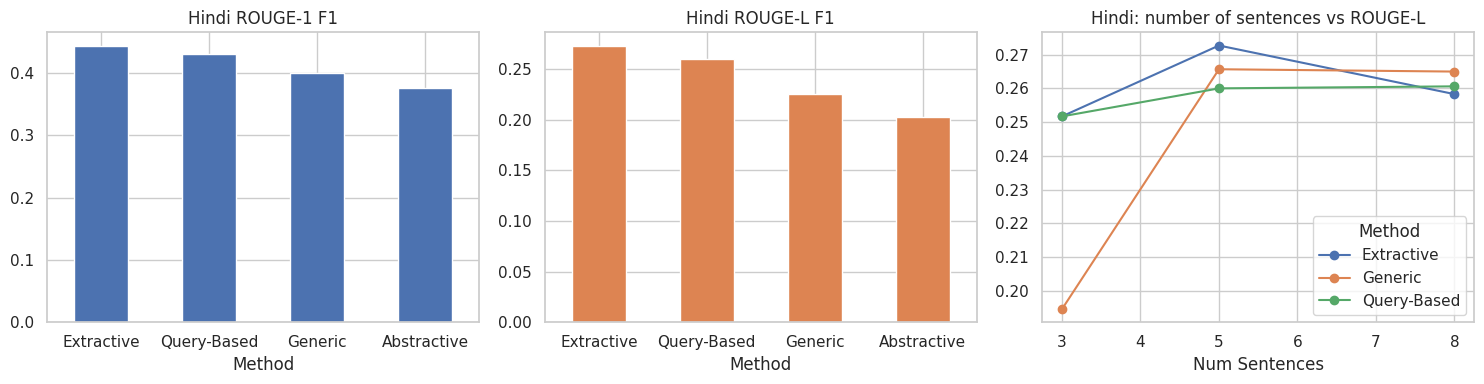

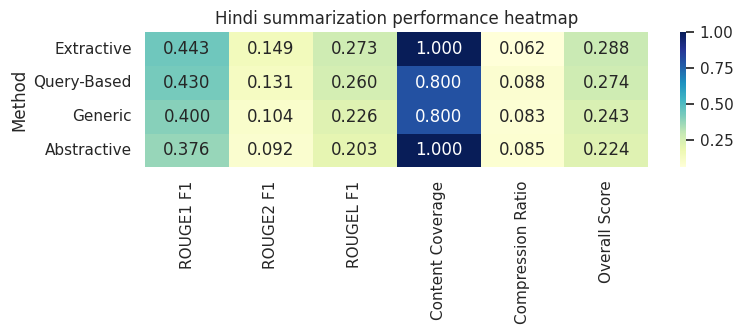

In [19]:
ratios, sent_counts, weights = [0.1, 0.2, 0.3], [3, 5, 8], [0.3, 0.5, 0.7]
tune = []
for r in ratios:
    for n in sent_counts:
        for name, fn in [
            ("Extractive", lambda: hi_extractive_summarizer(document_hi, r, n)),
            ("Query-Based", lambda: hi_query_based_summarizer(document_hi, query_hi, r, n)),
        ]:
            sc = hi_rouge(fn(), reference_summary_hi)
            tune.append(
                {
                    "Method": name,
                    "Summary Ratio": r,
                    "Num Sentences": n,
                    "Freq Weight": np.nan,
                    "ROUGE-1": sc["ROUGE1 F1"],
                    "ROUGE-2": sc["ROUGE2 F1"],
                    "ROUGE-L": sc["ROUGEL F1"],
                }
            )
        for w in weights:
            sc = hi_rouge(hi_generic_summarizer(document_hi, r, n, w), reference_summary_hi)
            tune.append(
                {
                    "Method": "Generic",
                    "Summary Ratio": r,
                    "Num Sentences": n,
                    "Freq Weight": w,
                    "ROUGE-1": sc["ROUGE1 F1"],
                    "ROUGE-2": sc["ROUGE2 F1"],
                    "ROUGE-L": sc["ROUGEL F1"],
                }
            )
df_tune_hi = pd.DataFrame(tune)
df_tune_hi["Overall"] = df_tune_hi[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].mean(axis=1)
best = df_tune_hi.loc[df_tune_hi["Overall"].idxmax()]
print("Best Hindi tuning configuration:")
print(best.to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
final_hi["ROUGE1 F1"].plot(kind="bar", ax=axes[0], color="#4c72b0", rot=0, title="Hindi ROUGE-1 F1")
final_hi["ROUGEL F1"].plot(kind="bar", ax=axes[1], color="#dd8452", rot=0, title="Hindi ROUGE-L F1")
df_tune_hi.groupby(["Num Sentences", "Method"])["ROUGE-L"].mean().unstack().plot(
    ax=axes[2], marker="o", title="Hindi: number of sentences vs ROUGE-L"
)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3.5))
sns.heatmap(final_hi.astype(float), annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Hindi summarization performance heatmap")
plt.tight_layout()
plt.show()

### D9. English vs Hindi comparison

,English (Part C run),Hindi
Extractive,0.147,0.2884
Abstractive,0.123,0.2236
Generic,0.179,0.2431
Query-Based,0.146,0.2738


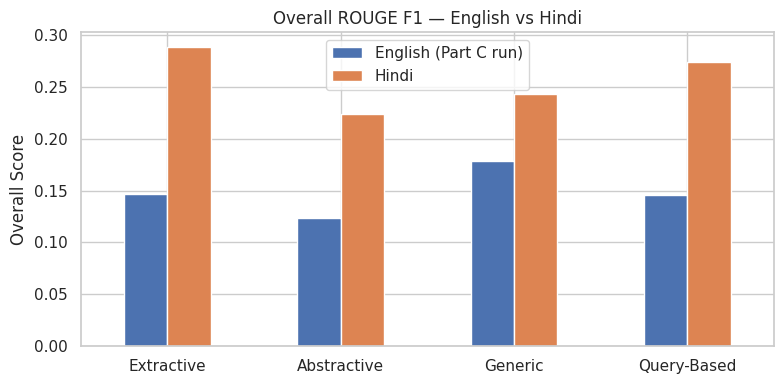

Best Hindi summarizer: Extractive  (overall 0.2884)

Notes on Hindi:
- Sentence splitting on '।' is required; punkt would treat a whole paragraph as one sentence.
- No lemmatiser was used, so inflected forms (प्रणाली / प्रणालियाँ / प्रणालियों) count as different words,
  which lowers frequency scores and ROUGE overlap compared with English.
- ROUGE needed a Devanagari-aware tokenizer; with the default tokenizer every score is 0.
- The abstractive model is mT5 (XL-Sum), not T5-small, because T5-small has no Hindi in its vocabulary.



In [20]:
# Uses df_all / final tables from Part C if they exist in this session; otherwise shows Hindi only.
try:
    en_overall = pd.Series(
        {"Extractive": 0.147, "Abstractive": 0.123, "Generic": 0.179, "Query-Based": 0.146},
        name="English (Part C run)",
    )
    cmp = pd.concat([en_overall, final_hi["Overall Score"].rename("Hindi")], axis=1)
    display(cmp)
    cmp.plot(kind="bar", figsize=(8, 4), rot=0, title="Overall ROUGE F1 — English vs Hindi")
    plt.ylabel("Overall Score")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Comparison skipped:", e)

best_hi = final_hi["Overall Score"].idxmax()
print(f"Best Hindi summarizer: {best_hi}  (overall {final_hi.loc[best_hi, 'Overall Score']:.4f})")
print("""
Notes on Hindi:
- Sentence splitting on '।' is required; punkt would treat a whole paragraph as one sentence.
- No lemmatiser was used, so inflected forms (प्रणाली / प्रणालियाँ / प्रणालियों) count as different words,
  which lowers frequency scores and ROUGE overlap compared with English.
- ROUGE needed a Devanagari-aware tokenizer; with the default tokenizer every score is 0.
- The abstractive model is mT5 (XL-Sum), not T5-small, because T5-small has no Hindi in its vocabulary.
""")